# Análise do Mercado Global de Vinhos (X-Wines) — RA1 e RA2

**Curso:** Sistemas de Informação · **Professora:** Marina de Lara · **Equipe:** João Guilherme Marques Camargo
**Repositório:** https://github.com/haku769/ra1-data-analytics

| Seção | Conteúdo | Ferramenta |
|---|---|---|
| **RA1** | Ingestão, diagnóstico de qualidade, limpeza e exportação da base X-Wines (21 milhões de avaliações) | Pandas |
| **RA2** | Monitoramento de novas avaliações com janelas temporais (tumbling de 10 min) | Spark Structured Streaming |

# RA1 — Ingestão, qualidade e preparação dos dados

**Nota de reprodutibilidade:** os arquivos originais `XWines_Full_100K_wines.csv` e `XWines_Full_21M_ratings.csv` excedem o limite de tamanho do GitHub. Para executar a RA1 do zero, baixe a base X-Wines e coloque os dois arquivos na mesma pasta deste notebook. A RA2 não depende desses arquivos.

## 1.1 Ingestão

Leitura dos dois CSVs e junção (*inner join*) pela chave `WineID`. Resultado: **21.013.536 linhas × 22 colunas**, em que cada linha é uma avaliação individual com os dados cadastrais do vinho.

In [ ]:
import pandas as pd

# 1. INGESTÃO DOS DADOS
print("Iniciando a leitura dos arquivos...")
df_wines = pd.read_csv('XWines_Full_100K_wines.csv')
df_ratings = pd.read_csv('XWines_Full_21M_ratings.csv')

print("Unindo as tabelas (Merge)...")
df_completo = pd.merge(df_ratings, df_wines, on='WineID', how='inner')

print(f"Ingestão concluída! O dataset possui {df_completo.shape[0]} linhas e {df_completo.shape[1]} colunas.")
display(df_completo.head())

## 1.2 Diagnóstico de qualidade

Principais achados nas saídas abaixo:
- **Nulos:** apenas `Website`, com 2.440.869 valores ausentes (~11,6% das linhas).
- **Outliers de ABV:** mínimo de 0% e máximo de 50%, valores impossíveis para vinho.
- **Tipos:** `Vintage` foi lida como `object` (mistura de anos e textos como safras não datadas), e `Date` como texto.

In [ ]:
# 2. AVALIAÇÃO DA QUALIDADE
print("--- INFORMAÇÕES GERAIS E TIPOS DE DADOS ---")
display(df_completo.info())

print("\n--- VALORES AUSENTES (NULOS) ---")
valores_nulos = df_completo.isnull().sum()
display(valores_nulos[valores_nulos > 0])

print("\n--- ESTATÍSTICAS DESCRITIVAS (Identificando Outliers no ABV) ---")
display(df_completo.describe())

## 1.3 Limpeza e preparação

- **D1:** remoção da coluna `Website` (irrelevante para as perguntas analíticas e com muitos nulos).
- **D2:** filtro de ABV realista (> 4% e ≤ 25%), que removeu **3.013 registros** (~0,014%).
- **D3:** `Vintage` convertida para inteiro anulável (`Int64`). Safras não numéricas viram nulas, cerca de 2% na amostra final. `Date` foi convertida para `datetime`.

In [ ]:
# 3. LIMPEZA E PREPARAÇÃO DOS DADOS
print("Iniciando a limpeza dos dados...")
df_clean = df_completo.copy()

# A. Removendo colunas desnecessárias
# Justificativa: A coluna 'Website' possui muitos valores nulos e não agrega valor à análise estatística.
if 'Website' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Website'])
    print("- Coluna 'Website' removida.")

# B. Tratamento de Outliers (Valores Inválidos)
# Justificativa: Filtrar Teor Alcoólico (ABV) para manter apenas bebidas reais (entre 4% e 25%).
qtd_antes = df_clean.shape[0]
df_clean = df_clean[(df_clean['ABV'] > 4.0) & (df_clean['ABV'] <= 25.0)]
qtd_depois = df_clean.shape[0]
print(f"- Removidos {qtd_antes - qtd_depois} registros com Teor Alcoólico (ABV) inválido ou extremo.")

# C. Correção de Tipos de Dados
# Justificativa: IDs e Safras são números inteiros, e a coluna Date precisa do formato datetime para análises futuras.
print("Corrigindo tipos de dados (aguarde, processando datas...)")
df_clean['WineID'] = df_clean['WineID'].astype(int)
df_clean['Vintage'] = pd.to_numeric(df_clean['Vintage'], errors='coerce')
df_clean['Vintage'] = df_clean['Vintage'].astype('Int64')
df_clean['Date'] = pd.to_datetime(df_clean['Date'], format='mixed')

print("\nLimpeza concluída com sucesso!")

## 1.4 Conjunto de dados resultante

Amostra aleatória reprodutível (`random_state=42`) de 100.000 linhas, salva em `x_wines_preparado_amostra.csv` para caber no limite de versionamento do GitHub.

In [ ]:
# 4. EXPORTAÇÃO DO CONJUNTO DE DADOS RESULTANTE
print("Gerando o arquivo final limpo...")

# Extraindo 100 mil linhas aleatórias para evitar estourar o limite de 100MB do GitHub
df_amostra = df_clean.sample(n=100000, random_state=42)
df_amostra.to_csv('x_wines_preparado_amostra.csv', index=False)

print("\n--- INFORMAÇÕES DO DATASET PREPARADO ---")
display(df_amostra.info())

print("\nArquivo 'x_wines_preparado_amostra.csv' gerado e pronto para a entrega!")
display(df_amostra.head())

# RA2 — Processamento em streaming com Spark Structured Streaming

> **Cenário A — projeto com dados estáticos.** A base X-Wines é fixa, por isso a chegada de novas avaliações é **simulada**: um pequeno conjunto de registros artificiais é gerado com vinhos reais do catálogo e publicado em lotes, em momentos diferentes, numa pasta monitorada pelo Spark.

A seção RA2 é **independente** da RA1 (não usa os CSVs de 21M de linhas). Para a demonstração em sala, basta reiniciar o kernel e executar a partir desta célula.

## 2.1 Objetivo da análise

**O que se deseja monitorar:** a **nota média** e o **volume de novas avaliações** que chegam para cada **tipo de vinho** (Red, White, Rosé, Dessert/Port), em intervalos fixos de 10 minutos.

**Por que isso é útil:** na RA1 a qualidade percebida foi analisada de forma estática (média histórica de 3,88). Em produção, uma plataforma de avaliações precisa perceber **mudanças recentes** — por exemplo, uma nova safra mal avaliada ou um pico de avaliações após uma promoção. Uma agregação por janela temporal responde à pergunta: *"nos últimos 10 minutos, quantas avaliações cada tipo de vinho recebeu e qual foi a nota média?"*, e permite sinalizar janelas cuja média caia abaixo de um limite de alerta (3,5).

## 2.2 Configuração do ambiente Spark

Decisões tomadas para o ambiente local (Windows):

- **`JAVA_HOME`** é definido no próprio notebook caso não exista no sistema (ajuste o caminho do JDK 11 da sua máquina).
- **`spark.hadoop.io.native.lib.available = false`** desativa as chamadas nativas do Hadoop, evitando o erro `UnsatisfiedLinkError: NativeIO$Windows.access0`.
- Se existir um `winutils.exe` em `C:\hadoop\bin`, o `HADOOP_HOME` é configurado automaticamente (necessário em algumas instalações para gravar o *checkpoint* do streaming).
- A pasta de trabalho do streaming fica **fora do OneDrive** (`C:\spark_ra2`), porque a sincronização bloqueia arquivos enquanto o Spark os lê.
- `spark.sql.shuffle.partitions = 4`: o volume é pequeno, e o padrão (200 partições) deixaria cada micro-lote desnecessariamente lento.
- Fuso horário da sessão fixado em UTC para que os limites das janelas sejam exatamente os horários dos eventos.

In [1]:
import os, sys, json, time, shutil, random
from pathlib import Path
from datetime import datetime, timedelta

import pandas as pd
import matplotlib.pyplot as plt

# --- Ambiente Java/Hadoop (apenas no Windows) ---------------------------------
if os.name == "nt":
    # Spark 3.5 exige Java 11 ou 17 (Java 23+ quebra com "getSubject is not supported").
    # Procura automaticamente um JDK 17 ou 11 nas pastas de instalação mais comuns.
    import glob
    candidatos = []
    for raiz in [r"C:\Program Files", r"C:\Program Files (x86)", os.path.expanduser(r"~\.jdks")]:
        for versao in ("17", "11"):
            candidatos += sorted(glob.glob(os.path.join(raiz, "*", f"jdk-{versao}*")) +
                                 glob.glob(os.path.join(raiz, f"jdk-{versao}*")) +
                                 glob.glob(os.path.join(raiz, "*", f"*{versao}*jdk*")), reverse=True)
    candidatos = [Path(c) for c in candidatos if (Path(c) / "bin" / "java.exe").exists()]
    if not candidatos:
        raise RuntimeError("Nenhum JDK 11 ou 17 encontrado. Instale com:  winget install Microsoft.OpenJDK.17  "
                           "e depois reinicie o VS Code.")
    JDK_PATH = candidatos[0]
    os.environ["JAVA_HOME"] = str(JDK_PATH)                     # força o JDK, ignorando o JAVA_HOME do sistema
    os.environ["PATH"] = str(JDK_PATH / "bin") + ";" + os.environ["PATH"]
    if Path(r"C:\hadoop\bin\winutils.exe").exists():
        os.environ["HADOOP_HOME"] = r"C:\hadoop"
        os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]
    BASE_DIR = Path(r"C:\spark_ra2")          # fora do OneDrive
else:
    BASE_DIR = Path.home() / "spark_ra2"

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import subprocess
java_bin = Path(os.environ["JAVA_HOME"]) / "bin" / "java" if "JAVA_HOME" in os.environ else "java"
print("Java em uso:", subprocess.run([str(java_bin), "-version"], capture_output=True, text=True).stderr.splitlines()[0])

# --- Pastas do streaming (recriadas a cada execução para uma demo limpa) -------
INPUT_DIR   = BASE_DIR / "entrada"      # pasta monitorada pelo Spark
STAGING_DIR = BASE_DIR / "preparo"      # onde cada lote é escrito antes de ser publicado
CKPT_DIR    = BASE_DIR / "checkpoint"   # estado do streaming (arquivos já lidos, agregações)
for d in (INPUT_DIR, STAGING_DIR, CKPT_DIR):
    shutil.rmtree(d, ignore_errors=True)
    d.mkdir(parents=True, exist_ok=True)

from pyspark import SparkContext
if SparkContext._gateway is not None:
    raise RuntimeError("Já existe um Java aberto neste kernel. Reinicie o kernel (Restart) e execute de novo.")

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (StructType, StructField, LongType, StringType,
                               DoubleType, TimestampType)

spark = (
    SparkSession.builder
    .appName("RA2-XWines-Streaming")
    .master("local[*]")
    .config("spark.hadoop.io.native.lib.available", "false")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print(f"Spark {spark.version} iniciado | Python {sys.version.split()[0]}")
print(f"Pasta monitorada: {INPUT_DIR}")

Java em uso: openjdk version "17.0.21.0.2" 2026-10-22 LTS
Spark 3.5.3 iniciado | Python 3.14.8
Pasta monitorada: C:\spark_ra2\entrada


## 2.3 Fonte: registros artificiais coerentes com o X-Wines

**Como os registros são criados:** cada registro tem o mesmo formato de uma linha de `XWines_Full_21M_ratings.csv` unida ao cadastro de vinhos (RA1). Foram usados **9 vinhos reais** do dataset (WineID, nome, tipo e país conferidos nas saídas da RA1). O `RatingID` continua a numeração da base (a RA1 termina em 21.013.536) e as notas seguem a escala do X-Wines (1,0 a 5,0 em passos de 0,5), com distribuição próxima da média histórica.

**Como a chegada é simulada:** os 63 registros são divididos em **4 lotes**, publicados um após o outro. Cada registro tem um `event_time` (momento em que a avaliação foi feita), e é sobre ele que a janela é calculada — não sobre o horário em que o arquivo chegou. Para tornar a demonstração mais rica, dois comportamentos reais foram incluídos de propósito:

| Lote | Registros | Horário dos eventos | Comportamento simulado |
|---|---|---|---|
| 1 | 15 | 20:00 – 20:09 | Fluxo normal |
| 2 | 15 | 20:10 – 20:19 | Fluxo normal |
| 3 | 18 | 20:20 – 20:29 **+ 3 eventos de 20:0x** | **Dados atrasados**: avaliações feitas às 20:0x que só chegam no 3º lote (ex.: app offline) |
| 4 | 15 | 20:30 – 20:39 | **Queda de qualidade**: os tintos passam a receber notas baixas (ex.: safra com defeito) |

A semente aleatória é fixa (`random.Random(42)`), então os resultados são reproduzíveis.

In [2]:

CATALOGO = [
    (136103, "Lambrusco Emilia",                "Red",          "Italy"),
    (111430, "Pomerol",                         "Red",          "France"),
    (179511, "Napa Valley Cabernet Sauvignon",  "Red",          "United States"),
    (168004, "Cabernet-Malbec",                 "Red",          "Argentina"),
    (106710, "Spätburgunder (Markgräflerland)", "Red",          "Germany"),
    (158877, "Albariño",                        "White",        "Spain"),
    (193793, "Rosé de Purcari",                 "Rosé",         "Moldova"),
    (144864, "Lambrusco Emilia Rosé",           "Rosé",         "Italy"),
    (104036, "Terrantez Madeira",               "Dessert/Port", "Portugal"),
]
NOTAS_NORMAIS = [3.0, 3.5, 4.0, 4.5, 5.0]; PESOS_NORMAIS = [10, 25, 35, 20, 10]   # média ~3,9
NOTAS_QUEDA   = [1.5, 2.0, 2.5, 3.0, 3.5]; PESOS_QUEDA   = [10, 25, 35, 20, 10]   # média ~2,5

rng = random.Random(42)
INICIO = datetime(2026, 11, 8, 20, 0, 0)
proximo_id = 21_013_537   # continua a numeração do dataset original

def gerar_registros(qtd, minuto_ini, minuto_fim, queda_tintos=False):
    """Gera 'qtd' avaliações com event_time aleatório entre minuto_ini e minuto_fim."""
    global proximo_id
    regs = []
    for _ in range(qtd):
        wine_id, nome, tipo, pais = rng.choice(CATALOGO)
        if queda_tintos and tipo == "Red":
            nota = rng.choices(NOTAS_QUEDA, PESOS_QUEDA)[0]
        else:
            nota = rng.choices(NOTAS_NORMAIS, PESOS_NORMAIS)[0]
        ts = INICIO + timedelta(minutes=rng.randint(minuto_ini, minuto_fim), seconds=rng.randint(0, 59))
        regs.append({"RatingID": proximo_id, "UserID": rng.randint(1_000_001, 2_063_390),
                     "WineID": wine_id, "WineName": nome, "Type": tipo, "Country": pais,
                     "Rating": nota, "event_time": ts.strftime("%Y-%m-%d %H:%M:%S")})
        proximo_id += 1
    return sorted(regs, key=lambda r: r["event_time"])

lotes = [
    gerar_registros(15, 0, 9),                                   # Lote 1
    gerar_registros(15, 10, 19),                                 # Lote 2
    gerar_registros(15, 20, 29) + gerar_registros(3, 3, 8),      # Lote 3 (+3 atrasados)
    gerar_registros(15, 30, 39, queda_tintos=True),              # Lote 4 (queda nos tintos)
]

resumo = pd.DataFrame([{"Lote": i, "Registros": len(l),
                        "Evento mais antigo": min(r["event_time"] for r in l)[11:],
                        "Evento mais recente": max(r["event_time"] for r in l)[11:]}
                       for i, l in enumerate(lotes, 1)])
display(resumo)
print("Exemplo de registro artificial:")
print(json.dumps(lotes[0][0], ensure_ascii=False, indent=2))

,Lote,Registros,Evento mais antigo,Evento mais recente
0,1,15,20:00:42,20:08:26
1,2,15,20:10:43,20:19:29
2,3,18,20:03:59,20:29:36
3,4,15,20:30:24,20:39:36


Exemplo de registro artificial:
{
  "RatingID": 21013546,
  "UserID": 1477938,
  "WineID": 168004,
  "WineName": "Cabernet-Malbec",
  "Type": "Red",
  "Country": "Argentina",
  "Rating": 4.5,
  "event_time": "2026-11-08 20:00:42"
}


## 2.4 Leitura em streaming

O Spark lê a pasta `entrada/` com `readStream` (*file source*). Decisões:

- **Esquema explícito**: em streaming o Spark não infere esquema; isso também garante que `event_time` seja lido como `timestamp`.
- **`maxFilesPerTrigger = 1`**: cada arquivo publicado vira um micro-lote, deixando visível a chegada de cada lote.
- **Publicação atômica**: o lote é escrito em `preparo/` e depois **movido** (`os.replace`) para `entrada/`. Assim o Spark nunca lê um arquivo pela metade — esse foi o problema de bloqueio visto com o OneDrive.

In [3]:
schema_avaliacao = StructType([
    StructField("RatingID",   LongType(),      False),
    StructField("UserID",     LongType(),      False),
    StructField("WineID",     LongType(),      False),
    StructField("WineName",   StringType(),    True),
    StructField("Type",       StringType(),    True),
    StructField("Country",    StringType(),    True),
    StructField("Rating",     DoubleType(),    True),
    StructField("event_time", TimestampType(), True),
])

avaliacoes_stream = (
    spark.readStream
    .schema(schema_avaliacao)
    .option("maxFilesPerTrigger", 1)
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .json(INPUT_DIR.as_uri())
)
print("É um DataFrame de streaming?", avaliacoes_stream.isStreaming)
avaliacoes_stream.printSchema()

É um DataFrame de streaming? True
root
 |-- RatingID: long (nullable = true)
 |-- UserID: long (nullable = true)
 |-- WineID: long (nullable = true)
 |-- WineName: string (nullable = true)
 |-- Type: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Rating: double (nullable = true)
 |-- event_time: timestamp (nullable = true)



## 2.5 Janela temporal e agregação

- **Tipo de janela:** **Tumbling** (janelas fixas, sem sobreposição) — cada avaliação pertence a exatamente um intervalo, o que facilita comparar períodos consecutivos e responder "como foi cada bloco de 10 minutos".
- **Duração:** **10 minutos**, sobre o `event_time` (tempo do evento). Não há deslocamento (*slide*), pois a janela é tumbling.
- **Agrupamento:** `window(event_time, "10 minutes")` + `Type`.
- **Agregações:** `count` (volume de avaliações), `avg` (nota média), `min` e `max` (amplitude das notas).
- **Modo de saída:** `complete` com *sink* em memória — a cada micro-lote a tabela inteira de resultados é reescrita, o que permite ver janelas antigas sendo **atualizadas** quando chegam dados atrasados. Não foi definido *watermark* justamente para aceitar esses atrasos; num sistema contínuo de produção usaríamos `withWatermark` para limitar o estado guardado.

In [4]:
JANELA = "10 minutes"

agregado_por_janela = (
    avaliacoes_stream
    .groupBy(F.window("event_time", JANELA).alias("janela"), F.col("Type"))
    .agg(
        F.count("Rating").alias("qtd_avaliacoes"),
        F.round(F.avg("Rating"), 2).alias("nota_media"),
        F.min("Rating").alias("nota_min"),
        F.max("Rating").alias("nota_max"),
    )
)

query = (
    agregado_por_janela.writeStream
    .outputMode("complete")
    .format("memory")
    .queryName("avaliacoes_por_janela")
    .option("checkpointLocation", CKPT_DIR.as_uri())
    .trigger(processingTime="2 seconds")
    .start()
)
print("Consulta de streaming ativa?", query.isActive)
print("ID da consulta:", query.id)

Consulta de streaming ativa? True
ID da consulta: 1b47de89-8fae-47cf-88bb-d0624afeb0c3


## 2.6 Simulação da chegada dos registros e resultados a cada lote

A célula abaixo publica um lote de cada vez, com uma pausa entre eles. Após cada publicação, `processAllAvailable()` aguarda o Spark processar o micro-lote e a tabela de resultados é consultada. A coluna **`alerta`** marca janelas com nota média abaixo de 3,5. A evolução mostra o streaming em funcionamento: a cada lote, **novas janelas aparecem** ou **janelas existentes são atualizadas**.

In [5]:
LIMITE_ALERTA = 3.5
historico = []          # guarda o resultado após cada lote, para comparação

def publicar_lote(registros, numero):
    """Escreve o lote em JSON Lines em 'preparo/' e o move atomicamente para 'entrada/'."""
    nome = f"lote_{numero:02d}.json"
    tmp = STAGING_DIR / nome
    with open(tmp, "w", encoding="utf-8") as f:
        for r in registros:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    os.replace(tmp, INPUT_DIR / nome)
    return nome

def resultado_atual():
    return spark.sql(f"""
        SELECT date_format(janela.start, 'HH:mm') AS inicio,
               date_format(janela.end,   'HH:mm') AS fim,
               Type AS tipo, qtd_avaliacoes, nota_media, nota_min, nota_max,
               CASE WHEN nota_media < {LIMITE_ALERTA} THEN 'ABAIXO DE {LIMITE_ALERTA}' ELSE '' END AS alerta
        FROM avaliacoes_por_janela
        ORDER BY janela.start, tipo
    """).toPandas()

for numero, registros in enumerate(lotes, start=1):
    time.sleep(3)   # intervalo entre chegadas
    arquivo = publicar_lote(registros, numero)
    query.processAllAvailable()

    linhas_recebidas = sum(p["numInputRows"] for p in query.recentProgress)
    df = resultado_atual()
    historico.append(df.assign(lote=numero))

    print("=" * 78)
    print(f"LOTE {numero} chegou às {datetime.now():%H:%M:%S} | arquivo {arquivo} | "
          f"{len(registros)} novos registros | total recebido pelo Spark: {linhas_recebidas}")
    print(f"Janelas no resultado: {df[['inicio','fim']].drop_duplicates().shape[0]}")
    print("=" * 78)
    display(df)

LOTE 1 chegou às 18:30:06 | arquivo lote_01.json | 15 novos registros | total recebido pelo Spark: 15
Janelas no resultado: 1


,inicio,fim,tipo,qtd_avaliacoes,nota_media,nota_min,nota_max,alerta
0,20:00,20:10,Red,9,3.94,3.0,5.0,
1,20:00,20:10,Rosé,5,3.50,3.0,4.0,
2,20:00,20:10,White,1,3.50,3.5,3.5,


LOTE 2 chegou às 18:30:12 | arquivo lote_02.json | 15 novos registros | total recebido pelo Spark: 30
Janelas no resultado: 2


,inicio,fim,tipo,qtd_avaliacoes,nota_media,nota_min,nota_max,alerta
0,20:00,20:10,Red,9,3.94,3.0,5.0,
1,20:00,20:10,Rosé,5,3.50,3.0,4.0,
2,20:00,20:10,White,1,3.50,3.5,3.5,
3,20:10,20:20,Dessert/Port,3,4.50,4.5,4.5,
4,20:10,20:20,Red,8,3.88,3.5,4.5,
5,20:10,20:20,Rosé,3,3.83,3.5,4.5,
6,20:10,20:20,White,1,4.00,4.0,4.0,


LOTE 3 chegou às 18:30:18 | arquivo lote_03.json | 18 novos registros | total recebido pelo Spark: 48
Janelas no resultado: 3


,inicio,fim,tipo,qtd_avaliacoes,nota_media,nota_min,nota_max,alerta
0,20:00,20:10,Dessert/Port,1,4.50,4.5,4.5,
1,20:00,20:10,Red,9,3.94,3.0,5.0,
2,20:00,20:10,Rosé,7,3.64,3.0,4.5,
3,20:00,20:10,White,1,3.50,3.5,3.5,
4,20:10,20:20,Dessert/Port,3,4.50,4.5,4.5,
5,20:10,20:20,Red,8,3.88,3.5,4.5,
6,20:10,20:20,Rosé,3,3.83,3.5,4.5,
7,20:10,20:20,White,1,4.00,4.0,4.0,
8,20:20,20:30,Dessert/Port,2,4.00,3.5,4.5,
9,20:20,20:30,Red,12,3.92,3.5,4.5,


LOTE 4 chegou às 18:30:24 | arquivo lote_04.json | 15 novos registros | total recebido pelo Spark: 63
Janelas no resultado: 4


,inicio,fim,tipo,qtd_avaliacoes,nota_media,nota_min,nota_max,alerta
0,20:00,20:10,Dessert/Port,1,4.50,4.5,4.5,
1,20:00,20:10,Red,9,3.94,3.0,5.0,
2,20:00,20:10,Rosé,7,3.64,3.0,4.5,
3,20:00,20:10,White,1,3.50,3.5,3.5,
4,20:10,20:20,Dessert/Port,3,4.50,4.5,4.5,
5,20:10,20:20,Red,8,3.88,3.5,4.5,
6,20:10,20:20,Rosé,3,3.83,3.5,4.5,
7,20:10,20:20,White,1,4.00,4.0,4.0,
8,20:20,20:30,Dessert/Port,2,4.00,3.5,4.5,
9,20:20,20:30,Red,12,3.92,3.5,4.5,


## 2.7 Evolução das janelas e visão consolidada

A primeira tabela mostra o **total de avaliações por janela após cada lote**: é a evidência direta de como o resultado muda com a chegada de novos dados. A segunda é a nota média final por janela e tipo, e o gráfico compara a média de cada tipo com o limite de alerta.

Total de avaliações por janela, após cada lote:


janela,20:00–20:10,20:10–20:20,20:20–20:30,20:30–20:40
após lote 1,15,0,0,0
após lote 2,15,15,0,0
após lote 3,18,15,15,0
após lote 4,18,15,15,15


Nota média final por janela (linhas) e tipo de vinho (colunas):


tipo,Dessert/Port,Red,Rosé,White
inicio,,,,
20:00,4.5,3.94,3.64,3.50
20:10,4.5,3.88,3.83,4.00
20:20,4.0,3.92,4.50,NaN
20:30,3.5,2.22,3.67,3.75


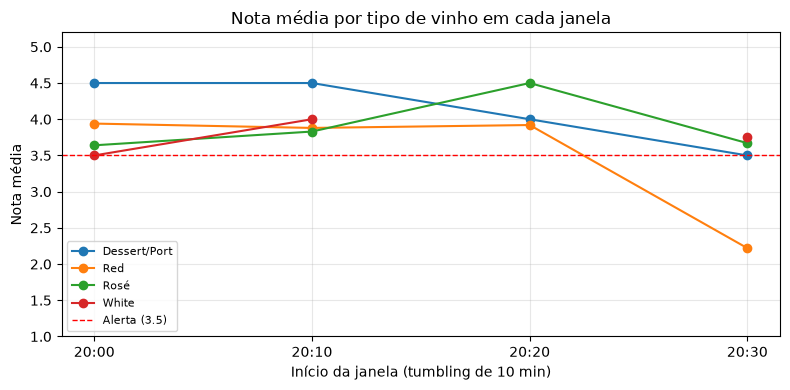

In [6]:
# Volume por janela após cada lote (soma de todos os tipos)
evolucao = (pd.concat(historico)
              .assign(janela=lambda d: d["inicio"] + "–" + d["fim"])
              .groupby(["lote", "janela"])["qtd_avaliacoes"].sum()
              .unstack("janela").fillna(0).astype(int))
evolucao.index = [f"após lote {i}" for i in evolucao.index]
print("Total de avaliações por janela, após cada lote:")
display(evolucao)

final = historico[-1]
pivo = final.pivot(index="inicio", columns="tipo", values="nota_media")
print("Nota média final por janela (linhas) e tipo de vinho (colunas):")
display(pivo)

fig, ax = plt.subplots(figsize=(8, 4))
for tipo in pivo.columns:
    ax.plot(pivo.index, pivo[tipo], marker="o", label=tipo)
ax.axhline(LIMITE_ALERTA, color="red", linestyle="--", linewidth=1, label=f"Alerta ({LIMITE_ALERTA})")
ax.set_xlabel("Início da janela (tumbling de 10 min)")
ax.set_ylabel("Nota média")
ax.set_ylim(1, 5.2)
ax.set_title("Nota média por tipo de vinho em cada janela")
ax.legend(loc="lower left", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.8 Resultados e interpretação

**Funcionamento do streaming.** Os 63 registros chegaram em 4 arquivos e foram processados em micro-lotes. O total recebido pelo Spark cresceu de forma incremental (15 → 30 → 48 → 63): cada arquivo novo foi detectado e só ele foi lido, enquanto o estado das agregações anteriores ficou guardado no *checkpoint*.

**Comportamento das janelas com a chegada de novos dados.**
- **Lotes 1 e 2** abriram as janelas 20:00–20:10 e 20:10–20:20, com 15 avaliações cada.
- **Lote 3** abriu a janela 20:20–20:30 e também **atualizou uma janela antiga**: a janela 20:00–20:10 passou de 15 para 18 avaliações. Os 3 registros atrasados (2 Rosé e 1 Dessert/Port, feitos às 20:0x) foram somados à janela do momento em que a avaliação ocorreu, e não à do momento em que chegaram. A nota média dos Rosé nessa janela passou de 3,50 para 3,64, e o tipo Dessert/Port apareceu nela. Isso mostra a diferença entre *tempo do evento* e *tempo de chegada* e por que a janela foi definida sobre `event_time`.
- **Lote 4** abriu a janela 20:30–20:40, onde os **tintos (Red) caíram para nota média 2,22** (9 avaliações, notas entre 1,5 e 2,5), contra cerca de 3,9 nas três janelas anteriores. Essa foi a única combinação janela/tipo marcada com alerta.

**Interpretação para o problema analítico.** Nas janelas "normais", as médias ficaram entre 3,5 e 4,5, coerentes com a média histórica de 3,88 calculada na RA1. A queda no último intervalo é **específica dos tintos**: Rosé (3,67), White (3,75) e Dessert/Port (3,50) se mantiveram estáveis. Ou seja, não é uma queda geral da plataforma, e sim um sinal que mereceria investigação (por exemplo, uma safra com problema). Esse tipo de leitura não aparece na média histórica estática e é exatamente o que a agregação por janela torna visível.

**Limitações.** Os dados são simulados e há poucas avaliações por janela. Alguns grupos têm só 1 registro (ex.: White às 20:00 e às 20:10), então a média desses grupos é instável e não deve ser usada sozinha para alertas; um critério melhor exigiria um volume mínimo por janela. Como não há *watermark*, o estado cresce indefinidamente. Num fluxo contínuo de produção seria necessário `withWatermark` (por exemplo, 15 minutos) e um *sink* persistente no lugar da memória.

## 2.9 Encerramento

A consulta de streaming e a sessão Spark são encerradas para liberar memória e o processo Java.

In [7]:
query.stop()
spark.stop()
print("Consulta de streaming e sessão Spark encerradas.")

Consulta de streaming e sessão Spark encerradas.
